In [1]:
import sys
import numpy as np
import h5py
import rasterio
import matplotlib.pyplot as plt

print("AQUAFUSION NISAR ENVIRONMENT")
print("----------------------------")
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("H5py:", h5py.__version__)
print("Environment ready!")

AQUAFUSION NISAR ENVIRONMENT
----------------------------
Python: 3.12.16 (main, Oct 26 2026, 11:31:43) [Clang 21.1.8 ]
NumPy: 2.5.4
H5py: 3.16.0
Environment ready!


In [2]:

from pathlib import Path

PROJECT = Path.home() / "Documents" / "AQUAFUSION_NISAR"

L_BAND_DIR = PROJECT / "DATA" / "L_BAND"
S_BAND_DIR = PROJECT / "DATA" / "S_BAND"

l_files = list(L_BAND_DIR.glob("*.h5"))
s_files = list(S_BAND_DIR.glob("*.h5"))

print("AQUAFUSION DATA INVENTORY")
print("=" * 50)

for label, files in [("L-BAND", l_files), ("S-BAND", s_files)]:
    print(f"\n{label}:")
    for file in files:
        print("Filename:", file.name)
        print("Size:", round(file.stat().st_size / 1024**3, 2), "GB")
        print("Exists:", file.exists())

assert len(l_files) >= 1, "L-band HDF5 file not found"
assert len(s_files) >= 1, "S-band HDF5 file not found"

L_FILE = l_files[0]
S_FILE = s_files[0]

print("\nBoth datasets located successfully!")


AQUAFUSION DATA INVENTORY

L-BAND:
Filename: NISAR_L2_PR_GCOV_034_098_A_014_4005_DHDH_A_20261030T233811_20261030T233845_P05036_N_F_J_001.h5
Size: 6.05 GB
Exists: True

S-BAND:
Filename: NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5
Size: 11.76 GB
Exists: True

Both datasets located successfully!


In [4]:

import os
import h5py

for label, filepath in [
    ("L-BAND", L_FILE),
    ("S-BAND", S_FILE)
]:
    print("\n", "=" * 45)
    print(label)
    print("File:", filepath.name)
    print("Size:", round(os.path.getsize(filepath) / 1e9, 3), "GB")

    try:
        with h5py.File(filepath, "r") as f:
            print("HDF5 status: VALID")
            print("Root groups:", list(f.keys()))
    except Exception as e:
        print("HDF5 status: ERROR")
        print(type(e).__name__, str(e))




L-BAND
File: NISAR_L2_PR_GCOV_034_098_A_014_4005_DHDH_A_20261030T233811_20261030T233845_P05036_N_F_J_001.h5
Size: 6.492 GB
HDF5 status: ERROR
OSError Unable to synchronously open file (truncated file: eof = 6492056689, sblock->base_addr = 0, stored_eof = 6798966784)

S-BAND
File: NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5
Size: 12.632 GB
HDF5 status: VALID
Root groups: ['complex64', 'science']


In [5]:

import h5py

print("=" * 65)
print("AQUAFUSION — S-BAND DATA STRUCTURE")
print("=" * 65)

with h5py.File(S_FILE, "r") as f:

    def inspect_structure(name, obj):
        if isinstance(obj, h5py.Group):
            print(f"\n📁 GROUP: {name}")

        elif isinstance(obj, h5py.Dataset):
            print(f"  📄 DATASET: {name}")
            print(f"     Shape: {obj.shape}")
            print(f"     Data type: {obj.dtype}")

    f.visititems(inspect_structure)

print("\nS-BAND STRUCTURE INSPECTION COMPLETE")


AQUAFUSION — S-BAND DATA STRUCTURE

📁 GROUP: science

📁 GROUP: science/SSAR

📁 GROUP: science/SSAR/GCOV

📁 GROUP: science/SSAR/GCOV/grids

📁 GROUP: science/SSAR/GCOV/grids/frequencyA
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/HHHH
     Shape: (33120, 34200)
     Data type: float32
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/HHHV
     Shape: (33120, 34200)
     Data type: complex64
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/HVHV
     Shape: (33120, 34200)
     Data type: float32
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/inputDataExceptionMask
     Shape: (33120, 34200)
     Data type: uint8
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/listOfCovarianceTerms
     Shape: (3,)
     Data type: |S4
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/listOfPolarizations
     Shape: (2,)
     Data type: |S2
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/mask
     Shape: (33120, 34200)
     Data type: uint8
  📄 DATASET: science/SSAR/GCOV/grids/frequencyA/numberOfLooks
     Sh

In [7]:

import h5py
import numpy as np

base = "science/SSAR/GCOV/grids/frequencyA"

print("AQUAFUSION — VALID PIXEL INVESTIGATION")

with h5py.File(S_FILE, "r") as f:

    for name in ["HHHH", "HVHV"]:

        ds = f[f"{base}/{name}"]

        print("\n" + "=" * 50)
        print("DATASET:", name)

        found = False
        window = 500

        # Search different raster locations
        for row in np.linspace(
            0, ds.shape[0] - window, 8, dtype=int
        ):
            for col in np.linspace(
                0, ds.shape[1] - window, 8, dtype=int
            ):

                sample = ds[
                    row:row+window,
                    col:col+window
                ]

                valid = sample[np.isfinite(sample)]

                if len(valid) > 0:

                    print("Valid pixels found!")
                    print("Window position:", row, col)
                    print("Valid pixel count:", len(valid))
                    print("Minimum:", valid.min())
                    print("Maximum:", valid.max())
                    print("Mean:", valid.mean())
                    print("Std deviation:", valid.std())

                    found = True
                    break

            if found:
                break

        if not found:
            print("No finite pixels found in sampled windows.")

    # Inspect mask metadata
    mask = f[f"{base}/mask"]

    print("\nMASK ATTRIBUTES:")
    for key, value in mask.attrs.items():
        print(key, ":", value)

print("\nINVESTIGATION COMPLETE")


AQUAFUSION — VALID PIXEL INVESTIGATION

DATASET: HHHH
Valid pixels found!
Window position: 4660 14442
Valid pixel count: 250000
Minimum: 0.0026495059
Maximum: 56.8507
Mean: 0.20173416
Std deviation: 0.33911914

DATASET: HVHV
Valid pixels found!
Window position: 4660 14442
Valid pixel count: 250000
Minimum: 0.0010834835
Maximum: 4.8907123
Mean: 0.052974403
Std deviation: 0.044955805

MASK ATTRIBUTES:
DIMENSION_LIST : [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
_FillValue : 255
description : b'Mask indicating the subswath number associated with valid GCOV samples. A GCOV sample is only considered valid if it is generated from fully-focused radar samples. If at least one radar sample in the averaging set is partially focused or invalid, the corresponding mask pixel will contain the value `0`. GCOV pixels outside of the radar acquisition extent are filled with the value `255`.'
grid_mapping : b'projection'
long_name : b'Valid samples sub

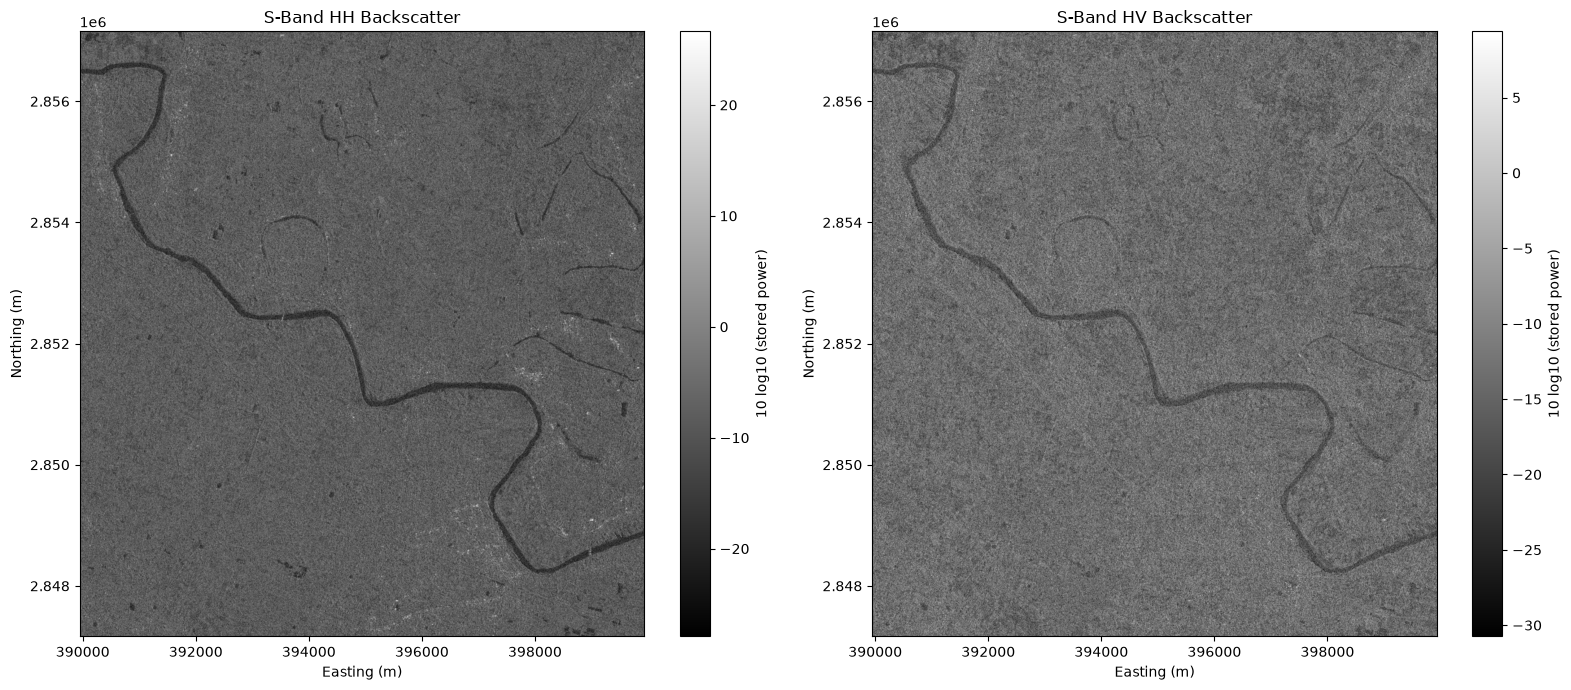

Valid mask pixels: 1000000
HH visualization complete
HV visualization complete


In [8]:

import h5py
import numpy as np
import matplotlib.pyplot as plt

base = "science/SSAR/GCOV/grids/frequencyA"

# Use the region where valid pixels were found
row_start = 4660
col_start = 14442
size = 1000

with h5py.File(S_FILE, "r") as f:

    # Read HH, HV and mask
    hh = f[f"{base}/HHHH"][
        row_start:row_start+size,
        col_start:col_start+size
    ]

    hv = f[f"{base}/HVHV"][
        row_start:row_start+size,
        col_start:col_start+size
    ]

    mask = f[f"{base}/mask"][
        row_start:row_start+size,
        col_start:col_start+size
    ]

    # Read spatial coordinates
    x = f[f"{base}/xCoordinates"][
        col_start:col_start+size
    ]

    y = f[f"{base}/yCoordinates"][
        row_start:row_start+size
    ]

# Valid GCOV pixels: exclude mask 0 and 255
valid_mask = (mask > 0) & (mask != 255)

def to_db(data):
    result = np.full(data.shape, np.nan, dtype=np.float32)

    valid = valid_mask & np.isfinite(data) & (data > 0)

    result[valid] = 10 * np.log10(data[valid])

    return result

hh_db = to_db(hh)
hv_db = to_db(hv)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

images = [
    (hh_db, "S-Band HH Backscatter"),
    (hv_db, "S-Band HV Backscatter")
]

for ax, (data, title) in zip(axes, images):

    im = ax.imshow(
        data,
        cmap="gray",
        origin="upper",
        extent=[x[0], x[-1], y[-1], y[0]],
        aspect="auto"
    )

    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

    plt.colorbar(im, ax=ax, label="10 log10 (stored power)")

plt.tight_layout()
plt.show()

print("Valid mask pixels:", np.count_nonzero(valid_mask))
print("HH visualization complete")
print("HV visualization complete")


In [9]:

from pyproj import Transformer

# Convert UTM Zone 45N coordinates to latitude/longitude
transformer = Transformer.from_crs(
    "EPSG:32645",
    "EPSG:4326",
    always_xy=True
)

# Centre of the selected image window
center_x = float(x[len(x)//2])
center_y = float(y[len(y)//2])

longitude, latitude = transformer.transform(
    center_x, center_y
)

print("GEOGRAPHIC LOCATION")
print("-------------------")
print("Easting:", center_x)
print("Northing:", center_y)
print("Longitude:", longitude)
print("Latitude:", latitude)

print("\nExpected Chennai location:")
print("Longitude: approximately 80.27")
print("Latitude: approximately 13.08")


GEOGRAPHIC LOCATION
-------------------
Easting: 394945.0
Northing: 2852155.0
Longitude: 85.95221273694716
Latitude: 25.78376138246302

Expected Chennai location:
Longitude: approximately 80.27
Latitude: approximately 13.08


In [10]:

from pyproj import Transformer

# Official reference centre
target_lon = 86.5000
target_lat = 25.5000

# Convert geographic coordinates to UTM Zone 45N
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32645",
    always_xy=True
)

target_x, target_y = transformer.transform(
    target_lon, target_lat
)

print("OFFICIAL STUDY AREA")
print("-------------------")
print("Target Easting:", target_x)
print("Target Northing:", target_y)

print("\nS-BAND DATASET EXTENT")
print("X minimum:", 245525.0)
print("X maximum:", 587515.0)
print("Y minimum:", 2572565.0)
print("Y maximum:", 2903755.0)

inside = (
    245525.0 <= target_x <= 587515.0
    and 2572565.0 <= target_y <= 2903755.0
)

print("\nOfficial reference centre inside S-band extent:", inside)


OFFICIAL STUDY AREA
-------------------
Target Easting: 449750.8413495597
Target Northing: 2820408.298110156

S-BAND DATASET EXTENT
X minimum: 245525.0
X maximum: 587515.0
Y minimum: 2572565.0
Y maximum: 2903755.0

Official reference centre inside S-band extent: True


In [11]:
from pathlib import Path

base = Path.home() / "Documents" / "AQUAFUSION_NISAR" / "DATA"

for band in ["L_BAND", "S_BAND"]:
    folder = base / band
    print(f"\n{band}")
    for f in folder.glob("*.h5"):
        print("File:", f.name)
        print("Size (GB):", round(f.stat().st_size / 1e9, 2))


L_BAND
File: NISAR_L2_PR_GCOV_034_098_A_014_4005_DHDH_A_20261030T233811_20261030T233845_P05036_N_F_J_001.h5
Size (GB): 6.8

S_BAND
File: NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5
Size (GB): 12.63


In [12]:
import h5py
from pathlib import Path

base = Path.home() / "Documents" / "AQUAFUSION_NISAR" / "DATA"

files = {
    "L-BAND": next((base / "L_BAND").glob("*.h5")),
    "S-BAND": next((base / "S_BAND").glob("*.h5"))
}

for band, filepath in files.items():

    print("\n", "="*60)
    print(band)
    print("="*60)

    with h5py.File(filepath, "r") as f:

        print("\nROOT ATTRIBUTES:")
        for key, value in f.attrs.items():
            print(key, ":", value)

        print("\nDATASET STRUCTURE:")

        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(
                    name,
                    "| Shape:", obj.shape,
                    "| Type:", obj.dtype
                )

        f.visititems(inspect)


L-BAND

ROOT ATTRIBUTES:
Conventions : b'CF-1.7'
contact : b'nisar-sds-ops@jpl.nasa.gov'
institution : b'NASA JPL'
mission_name : b'NISAR'
reference_document : b'D-102274 NISAR NASA SDS Product Specification Level-2 Geocoded Polarimetric Covariance L2 GCOV'
title : b'NISAR L2 GCOV Product'

DATASET STRUCTURE:
science/LSAR/GCOV/grids/frequencyA/HHHH | Shape: (33696, 34344) | Type: float32
science/LSAR/GCOV/grids/frequencyA/HVHV | Shape: (33696, 34344) | Type: float32
science/LSAR/GCOV/grids/frequencyA/inputDataExceptionMask | Shape: (33696, 34344) | Type: uint16
science/LSAR/GCOV/grids/frequencyA/listOfCovarianceTerms | Shape: (2,) | Type: |S4
science/LSAR/GCOV/grids/frequencyA/listOfPolarizations | Shape: (2,) | Type: |S2
science/LSAR/GCOV/grids/frequencyA/mask | Shape: (33696, 34344) | Type: uint8
science/LSAR/GCOV/grids/frequencyA/numberOfLooks | Shape: (33696, 34344) | Type: float32
science/LSAR/GCOV/grids/frequencyA/numberOfSubSwaths | Shape: () | Type: uint8
science/LSAR/GCOV/gri

In [13]:
import h5py
import numpy as np
from pathlib import Path

base = Path.home() / "Documents" / "AQUAFUSION_NISAR" / "DATA"

files = {
    "L-BAND": next((base / "L_BAND").glob("*.h5")),
    "S-BAND": next((base / "S_BAND").glob("*.h5"))
}

for band, filepath in files.items():

    group = "LSAR" if band == "L-BAND" else "SSAR"

    print("\n", "="*55)
    print(band)
    print("="*55)

    with h5py.File(filepath, "r") as f:

        root = f[f"science/{group}/GCOV/grids/frequencyA"]

        print("Available layers:")

        for key in root.keys():
            if isinstance(root[key], h5py.Dataset):
                print(key, root[key].shape, root[key].dtype)

        print("\nGRID INFORMATION")

        for key in [
            "projection",
            "xCoordinateSpacing",
            "yCoordinateSpacing"
        ]:
            if key in root:
                print(key, ":", root[key][()])

        x = root["xCoordinates"][:]
        y = root["yCoordinates"][:]

        print("\nCOORDINATE EXTENT")
        print("X:", x.min(), "to", x.max())
        print("Y:", y.min(), "to", y.max())

        print("\nCOVARIANCE TERM INFORMATION")

        if "listOfCovarianceTerms" in root:
            print(root["listOfCovarianceTerms"][:])

        if "listOfPolarizations" in root:
            print(root["listOfPolarizations"][:])

        print("\nMASK INFORMATION")

        mask = root["mask"]

        sample = mask[::100, ::100]

        print("Mask sample values:", np.unique(sample))


L-BAND
Available layers:
HHHH (33696, 34344) float32
HVHV (33696, 34344) float32
inputDataExceptionMask (33696, 34344) uint16
listOfCovarianceTerms (2,) |S4
listOfPolarizations (2,) |S2
mask (33696, 34344) uint8
numberOfLooks (33696, 34344) float32
numberOfSubSwaths () uint8
projection () uint32
rtcGammaToSigmaFactor (33696, 34344) float32
xCoordinateSpacing () float64
xCoordinates (34344,) float64
yCoordinateSpacing () float64
yCoordinates (33696,) float64

GRID INFORMATION
projection : 32645
xCoordinateSpacing : 10.0
yCoordinateSpacing : -10.0

COORDINATE EXTENT
X: 244805.0 to 588235.0
Y: 2569685.0 to 2906635.0

COVARIANCE TERM INFORMATION
[b'HHHH' b'HVHV']
[b'HH' b'HV']

MASK INFORMATION
Mask sample values: [  0   1 255]

S-BAND
Available layers:
HHHH (33120, 34200) float32
HHHV (33120, 34200) complex64
HVHV (33120, 34200) float32
inputDataExceptionMask (33120, 34200) uint8
listOfCovarianceTerms (3,) |S4
listOfPolarizations (2,) |S2
mask (33120, 34200) uint8
numberOfLooks (33120, 3

In [14]:
import h5py
import numpy as np
from pathlib import Path

base = Path.home() / "Documents" / "AQUAFUSION_NISAR" / "DATA"

folders = {
    "L-band": base / "L_BAND",
    "S-band": base / "S_BAND",
}

# Find one HDF5 product in each folder, with a clear error if either is missing.
files = {}
for band, folder in folders.items():
    candidates = sorted(folder.glob("*.h5"))
    if not candidates:
        raise FileNotFoundError(f"No .h5 file found in {folder}")
    files[band] = candidates[0]
    print(f"{band} file: {candidates[0].name}")

for band, filepath in files.items():
    group = "LSAR" if band == "L-band" else "SSAR"
    grid_path = f"science/{group}/GCOV/grids/frequencyA"

    print(f"\n{'=' * 60}\n{band.upper()}\n{'=' * 60}")

    with h5py.File(filepath, "r") as f:
        if grid_path not in f:
            print(f"Grid not found: {grid_path}")
            print("Available frequency grids:")
            f.visit(lambda name: print(name) if "grids/frequency" in name else None)
            continue

        grid = f[grid_path]

        print("Grid:", grid_path)
        print("Raster dimensions (rows, columns):",
              grid["HHHH"].shape if "HHHH" in grid else "HHHH not found")

        print("\nAvailable datasets:")
        for name, obj in grid.items():
            if isinstance(obj, h5py.Dataset):
                print(f"  {name}: shape={obj.shape}, dtype={obj.dtype}")

        print("\nGrid metadata:")
        for key in ("projection", "xCoordinateSpacing", "yCoordinateSpacing"):
            if key in grid:
                value = grid[key][()]
                print(f"  {key}: {value}")
            else:
                print(f"  {key}: not present in this grid group")

        for name in ("xCoordinates", "yCoordinates"):
            if name in grid:
                coords = grid[name][:]
                step = coords[1] - coords[0] if coords.size > 1 else np.nan
                print(
                    f"  {name}: count={coords.size}, "
                    f"first={coords[0]}, last={coords[-1]}, "
                    f"min={coords.min()}, max={coords.max()}, "
                    f"step≈{step}"
                )
            else:
                print(f"  {name}: not found")

        print("\nCovariance terms and polarizations:")
        for name in ("listOfCovarianceTerms", "listOfPolarizations"):
            if name in grid:
                print(f"  {name}: {grid[name][:]}")
            else:
                print(f"  {name}: not found in this grid group")

        print("\nMask:")
        if "mask" in grid:
            mask = grid["mask"]
            # Decimated sample to avoid reading the entire mask.
            sample = mask[::100, ::100]
            print("  Sampled values:", np.unique(sample, return_counts=True))
            print("  Attributes:", dict(mask.attrs))
        else:
            print("  No mask dataset found in this grid group")

L-band file: NISAR_L2_PR_GCOV_034_098_A_014_4005_DHDH_A_20261030T233811_20261030T233845_P05036_N_F_J_001.h5
S-band file: NISAR_S2_UR_GCOV_034_098_A_014_3700_DHNA_A_20261030T233811_20261030T233847_P00500_M_F_I_001.h5

L-BAND
Grid: science/LSAR/GCOV/grids/frequencyA
Raster dimensions (rows, columns): (33696, 34344)

Available datasets:
  HHHH: shape=(33696, 34344), dtype=float32
  HVHV: shape=(33696, 34344), dtype=float32
  inputDataExceptionMask: shape=(33696, 34344), dtype=uint16
  listOfCovarianceTerms: shape=(2,), dtype=|S4
  listOfPolarizations: shape=(2,), dtype=|S2
  mask: shape=(33696, 34344), dtype=uint8
  numberOfLooks: shape=(33696, 34344), dtype=float32
  numberOfSubSwaths: shape=(), dtype=uint8
  projection: shape=(), dtype=uint32
  rtcGammaToSigmaFactor: shape=(33696, 34344), dtype=float32
  xCoordinateSpacing: shape=(), dtype=float64
  xCoordinates: shape=(34344,), dtype=float64
  yCoordinateSpacing: shape=(), dtype=float64
  yCoordinates: shape=(33696,), dtype=float64

Gr

In [15]:
from pyproj import Transformer
import h5py
import numpy as np

target_x = 449750.84
target_y = 2820408.30

products = {
    "L-band": (files["L-band"], "LSAR"),
    "S-band": (files["S-band"], "SSAR"),
}

centres = {}

for band, (filepath, group_name) in products.items():
    grid_path = f"science/{group_name}/GCOV/grids/frequencyA"

    with h5py.File(filepath, "r") as f:
        grid = f[grid_path]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]

        col = int(np.argmin(np.abs(x - target_x)))
        row = int(np.argmin(np.abs(y - target_y)))
        mask_value = int(grid["mask"][row, col])

        centres[band] = (x, y)

        print(f"\n{band}")
        print(f"  Centre pixel row, col: {row}, {col}")
        print(f"  Pixel coordinate: E={x[col]:.2f}, N={y[row]:.2f}")
        print(f"  Mask value at nearest pixel: {mask_value}")
        print(f"  Centre pixel valid by mask: {mask_value not in (0, 255)}")

# Common coordinate extent
lx, ly = centres["L-band"]
sx, sy = centres["S-band"]

common_x_min = max(lx.min(), sx.min())
common_x_max = min(lx.max(), sx.max())
common_y_min = max(ly.min(), sy.min())
common_y_max = min(ly.max(), sy.max())

print("\nCommon coordinate bounds")
print(f"  X: {common_x_min:.1f} to {common_x_max:.1f} m")
print(f"  Y: {common_y_min:.1f} to {common_y_max:.1f} m")
print(f"  Official centre inside common bounds: "
      f"{common_x_min <= target_x <= common_x_max and common_y_min <= target_y <= common_y_max}")


L-band
  Centre pixel row, col: 8623, 20495
  Pixel coordinate: E=449755.00, N=2820405.00
  Mask value at nearest pixel: 1
  Centre pixel valid by mask: True

S-band
  Centre pixel row, col: 8335, 20423
  Pixel coordinate: E=449755.00, N=2820405.00
  Mask value at nearest pixel: 1
  Centre pixel valid by mask: True

Common coordinate bounds
  X: 245525.0 to 587515.0 m
  Y: 2572565.0 to 2903755.0 m
  Official centre inside common bounds: True


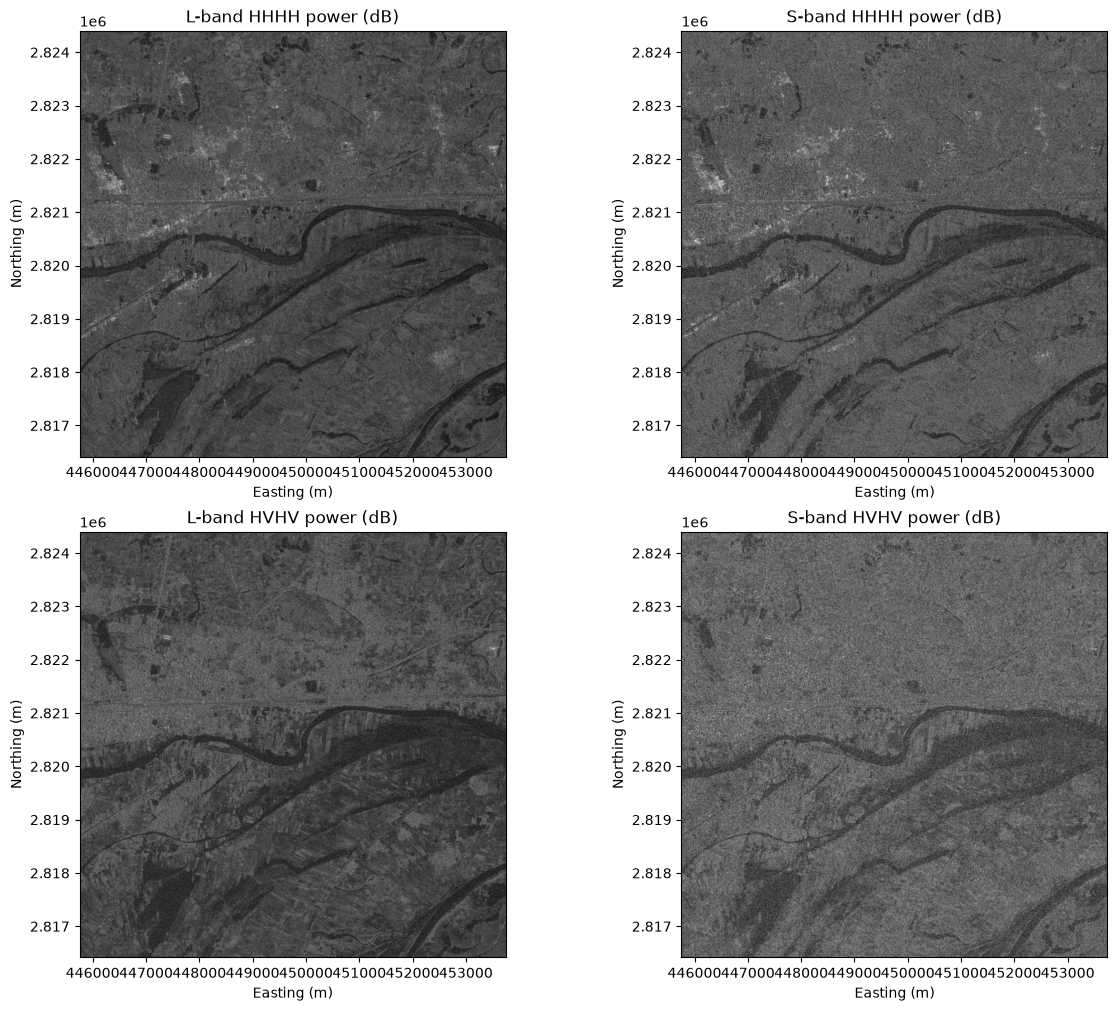

In [16]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

target_x = 449750.84
target_y = 2820408.30
size = 800

products = {
    "L-band": (files["L-band"], "LSAR"),
    "S-band": (files["S-band"], "SSAR"),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for col, (band, (filepath, group_name)) in enumerate(products.items()):
    grid_path = f"science/{group_name}/GCOV/grids/frequencyA"

    with h5py.File(filepath, "r") as f:
        grid = f[grid_path]

        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]

        center_col = int(np.argmin(np.abs(x - target_x)))
        center_row = int(np.argmin(np.abs(y - target_y)))

        half = size // 2
        row0 = max(0, center_row - half)
        row1 = min(len(y), row0 + size)
        col0 = max(0, center_col - half)
        col1 = min(len(x), col0 + size)
        window = np.s_[row0:row1, col0:col1]

        mask = grid["mask"][window]
        valid = (mask > 0) & (mask != 255)

        for row, layer_name in enumerate(("HHHH", "HVHV")):
            power = grid[layer_name][window]
            usable = valid & np.isfinite(power) & (power > 0)

            image_db = np.full(power.shape, np.nan, dtype=np.float32)
            image_db[usable] = 10 * np.log10(power[usable])

            ax = axes[row, col]
            ax.imshow(
                image_db,
                cmap="gray",
                origin="upper",
                extent=(x[col0], x[col1 - 1], y[row1 - 1], y[row0]),
                aspect="equal",
            )
            ax.set_title(f"{band} {layer_name} power (dB)")
            ax.set_xlabel("Easting (m)")
            ax.set_ylabel("Northing (m)")

            if not np.any(usable):
                ax.text(
                    0.5, 0.5, "No valid positive samples in window",
                    transform=ax.transAxes, ha="center", va="center"
                )

plt.show()

In [17]:
import h5py
import numpy as np

target_x = 449750.84
target_y = 2820408.30
size = 800

arrays = {}

for band, (filepath, group_name) in products.items():
    grid_path = f"science/{group_name}/GCOV/grids/frequencyA"

    with h5py.File(filepath, "r") as f:
        grid = f[grid_path]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]

        center_col = int(np.argmin(np.abs(x - target_x)))
        center_row = int(np.argmin(np.abs(y - target_y)))

        half = size // 2
        row0, row1 = center_row - half, center_row + half
        col0, col1 = center_col - half, center_col + half

        window = np.s_[row0:row1, col0:col1]

        mask = grid["mask"][window]
        hh = grid["HHHH"][window]
        hv = grid["HVHV"][window]

        valid = (
            (mask > 0) & (mask != 255)
            & np.isfinite(hh) & np.isfinite(hv)
            & (hh > 0) & (hv > 0)
        )

        arrays[band] = {
            "x": x[col0:col1],
            "y": y[row0:row1],
            "hh": hh,
            "hv": hv,
            "valid": valid,
        }

# Coordinate-based intersection: these pixel coordinate vectors match in this window.
x_common = np.intersect1d(arrays["L-band"]["x"], arrays["S-band"]["x"])
y_common = np.intersect1d(arrays["L-band"]["y"], arrays["S-band"]["y"])

if len(x_common) == 0 or len(y_common) == 0:
    raise ValueError("No exactly matching pixel coordinates in the selected windows.")

print("Common coordinate pixels:", len(y_common), "rows ×", len(x_common), "columns")

# Locate the common coordinate rectangle inside each window.
for band in ("L-band", "S-band"):
    a = arrays[band]
    r0 = int(np.where(a["y"] == y_common[0])[0][0])
    c0 = int(np.where(a["x"] == x_common[0])[0][0])

    # Coordinate arrays run north-to-south; use the same ordered intersection.
    h, w = len(y_common), len(x_common)
    arrays[band]["hh_common"] = a["hh"][r0:r0+h, c0:c0+w]
    arrays[band]["hv_common"] = a["hv"][r0:r0+h, c0:c0+w]
    arrays[band]["valid_common"] = a["valid"][r0:r0+h, c0:c0+w]

joint_valid = arrays["L-band"]["valid_common"] & arrays["S-band"]["valid_common"]
print("Jointly valid pixels:", int(joint_valid.sum()), "of", joint_valid.size)

for band in ("L-band", "S-band"):
    print(f"\n{band}")
    for pol, key in (("HH", "hh_common"), ("HV", "hv_common")):
        values = arrays[band][key][joint_valid]
        db = 10 * np.log10(values)
        print(
            f"  {pol} dB percentiles "
            f"(2, 50, 98): {np.percentile(db, [2, 50, 98]).round(2)}"
        )

Common coordinate pixels: 800 rows × 800 columns
Jointly valid pixels: 800 of 800

L-band
  HH dB percentiles (2, 50, 98): [-18.41  -9.59  -3.38]
  HV dB percentiles (2, 50, 98): [-25.89 -18.44 -10.35]

S-band
  HH dB percentiles (2, 50, 98): [-18.33  -8.85  -2.77]
  HV dB percentiles (2, 50, 98): [-22.78 -15.85  -9.65]


L-band: exploratory low-HH cutoff=-14.89 dB; candidate pixels=80 / 800
S-band: exploratory low-HH cutoff=-14.40 dB; candidate pixels=80 / 800


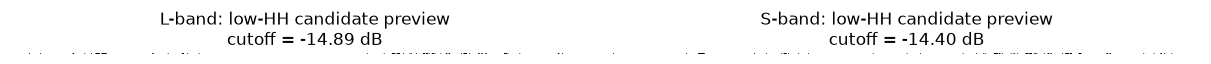

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Shared valid footprint from the preceding cell.
joint_valid = arrays["L-band"]["valid_common"] & arrays["S-band"]["valid_common"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, band in zip(axes, ("L-band", "S-band")):
    hh = arrays[band]["hh_common"]

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    usable = joint_valid & np.isfinite(hh) & (hh > 0)
    hh_db[usable] = 10 * np.log10(hh[usable])

    # Exploratory cutoff: lower 10th percentile of HH power in this window.
    threshold_db = np.percentile(hh_db[usable], 10)
    candidate = usable & (hh_db <= threshold_db)

    preview = np.ma.masked_where(~joint_valid, candidate.astype(np.uint8))

    ax.imshow(preview, cmap="gray_r", vmin=0, vmax=1, origin="upper")
    ax.set_title(f"{band}: low-HH candidate preview\ncutoff = {threshold_db:.2f} dB")
    ax.set_axis_off()

    print(
        f"{band}: exploratory low-HH cutoff={threshold_db:.2f} dB; "
        f"candidate pixels={int(candidate.sum())} / {int(joint_valid.sum())}"
    )

plt.show()

In [19]:
print("joint_valid shape:", joint_valid.shape)
print("joint_valid pixels:", int(np.count_nonzero(joint_valid)))

for band in ("L-band", "S-band"):
    hh = arrays[band]["hh_common"]
    valid = arrays[band]["valid_common"]

    print(
        f"{band}: HH shape={hh.shape}, "
        f"valid shape={valid.shape}, "
        f"valid pixels={int(np.count_nonzero(valid))}"
    )

joint_valid shape: (1, 800)
joint_valid pixels: 800
L-band: HH shape=(1, 800), valid shape=(1, 800), valid pixels=800
S-band: HH shape=(1, 800), valid shape=(1, 800), valid pixels=800


In [20]:
import h5py
import numpy as np

target_x = 449750.84
target_y = 2820408.30
size = 800

arrays = {}

for band, (filepath, group_name) in products.items():
    grid_path = f"science/{group_name}/GCOV/grids/frequencyA"

    with h5py.File(filepath, "r") as f:
        grid = f[grid_path]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]

        center_col = int(np.argmin(np.abs(x - target_x)))
        center_row = int(np.argmin(np.abs(y - target_y)))

        row0 = center_row - size // 2
        row1 = row0 + size
        col0 = center_col - size // 2
        col1 = col0 + size

        # Confirm the requested window fits inside this raster.
        if row0 < 0 or col0 < 0 or row1 > len(y) or col1 > len(x):
            raise ValueError(f"{band}: requested window extends outside the raster")

        sl = np.s_[row0:row1, col0:col1]
        mask = grid["mask"][sl]
        hh = grid["HHHH"][sl]
        hv = grid["HVHV"][sl]

        arrays[band] = {
            "x": x[col0:col1],
            "y": y[row0:row1],
            "hh": hh,
            "hv": hv,
            "valid": (mask > 0) & (mask != 255),
        }

    print(
        f"{band}: HH {arrays[band]['hh'].shape}, "
        f"HV {arrays[band]['hv'].shape}, "
        f"mask {arrays[band]['valid'].shape}"
    )

assert all(arrays[b]["hh"].shape == (size, size) for b in products)
print("Both full windows confirmed.")

L-band: HH (800, 800), HV (800, 800), mask (800, 800)
S-band: HH (800, 800), HV (800, 800), mask (800, 800)
Both full windows confirmed.


In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Match pixel coordinates explicitly, rather than assuming equal array indices.
x_common = np.intersect1d(arrays["L-band"]["x"], arrays["S-band"]["x"])
y_common = np.intersect1d(arrays["L-band"]["y"], arrays["S-band"]["y"])

if x_common.size == 0 or y_common.size == 0:
    raise ValueError("No exactly shared coordinates in these windows.")

aligned = {}
for band in ("L-band", "S-band"):
    a = arrays[band]
    rows = np.searchsorted(a["y"], y_common)
    cols = np.searchsorted(a["x"], x_common)

    aligned[band] = {
        "hh": a["hh"][np.ix_(rows, cols)],
        "hv": a["hv"][np.ix_(rows, cols)],
        "valid": a["valid"][np.ix_(rows, cols)],
    }

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]
print("Shared grid:", len(y_common), "rows ×", len(x_common), "columns")
print("Jointly valid pixels:", int(joint_valid.sum()), "of", joint_valid.size)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, band in zip(axes, ("L-band", "S-band")):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    cutoff = np.percentile(hh_db[usable], 10)
    candidates = usable & (hh_db <= cutoff)

    ax.imshow(
        np.ma.masked_where(~joint_valid, candidates),
        cmap="gray_r",
        vmin=0,
        vmax=1,
        origin="upper",
        aspect="equal",
    )
    ax.set_title(f"{band} exploratory low-HH\n10th percentile = {cutoff:.2f} dB")
    ax.set_axis_off()

    print(
        f"{band}: cutoff={cutoff:.2f} dB; "
        f"candidate pixels={int(candidates.sum())} / {int(joint_valid.sum())}"
    )

plt.show()

IndexError: index 800 is out of bounds for axis 0 with size 800

Shared grid: 800 rows × 800 columns
Jointly valid pixels: 640000 of 640000
L-band: cutoff=-15.02 dB; candidates=64000 / 640000
S-band: cutoff=-14.51 dB; candidates=64000 / 640000


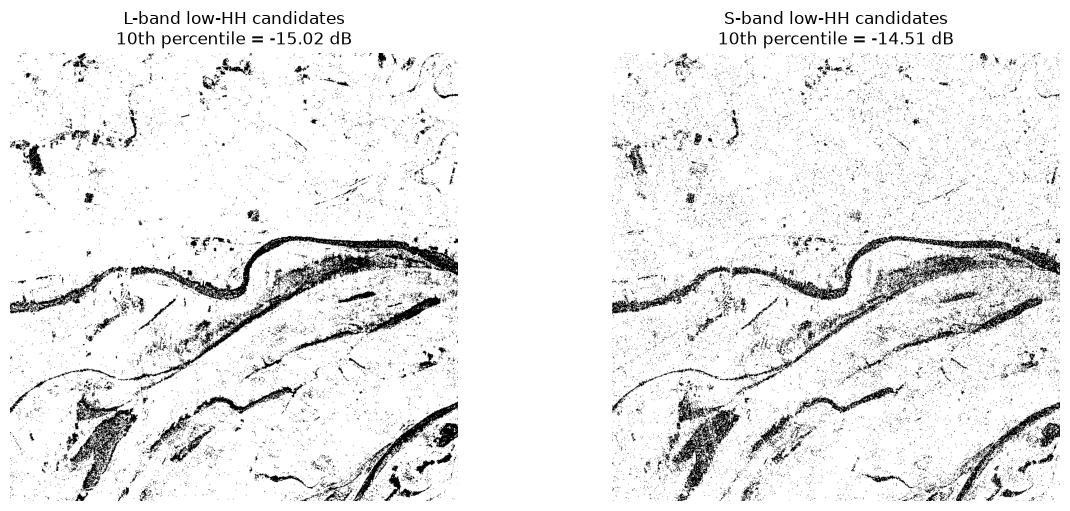

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Use the L-band window's pixel coordinates as the comparison grid.
x_ref = arrays["L-band"]["x"]
y_ref = arrays["L-band"]["y"]  # Descending: north to south

# Map each reference coordinate to its nearest S-band index.
s_x = arrays["S-band"]["x"]
s_y = arrays["S-band"]["y"]

x_idx_s = np.abs(s_x[None, :] - x_ref[:, None]).argmin(axis=1)
y_idx_s = np.abs(s_y[None, :] - y_ref[:, None]).argmin(axis=1)

# Keep only coordinates that match exactly (within floating point tolerance).
x_match = np.isclose(s_x[x_idx_s], x_ref, atol=1e-6)
y_match = np.isclose(s_y[y_idx_s], y_ref, atol=1e-6)

x_ref = x_ref[x_match]
y_ref = y_ref[y_match]
x_idx_s = x_idx_s[x_match]
y_idx_s = y_idx_s[y_match]

if x_ref.size == 0 or y_ref.size == 0:
    raise ValueError("No shared pixel coordinates found.")

# Select corresponding rows and columns. This works with descending Y.
aligned = {}
for band in ("L-band", "S-band"):
    if band == "L-band":
        rows = np.flatnonzero(y_match)
        cols = np.flatnonzero(x_match)
    else:
        rows = y_idx_s
        cols = x_idx_s

    a = arrays[band]
    aligned[band] = {
        "hh": a["hh"][np.ix_(rows, cols)],
        "valid": a["valid"][np.ix_(rows, cols)],
    }

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]

print("Shared grid:", len(y_ref), "rows ×", len(x_ref), "columns")
print("Jointly valid pixels:", int(joint_valid.sum()), "of", joint_valid.size)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, band in zip(axes, ("L-band", "S-band")):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    cutoff = np.percentile(hh_db[usable], 10)
    candidates = usable & (hh_db <= cutoff)

    ax.imshow(candidates, cmap="gray_r", vmin=0, vmax=1, origin="upper")
    ax.set_title(f"{band} low-HH candidates\n10th percentile = {cutoff:.2f} dB")
    ax.set_axis_off()

    print(
        f"{band}: cutoff={cutoff:.2f} dB; "
        f"candidates={int(candidates.sum())} / {int(joint_valid.sum())}"
    )

plt.show()

L-band: HH cutoff=-15.02 dB; HV cutoff=-23.01 dB; low-HH=64000; low-HH+HV=35590
S-band: HH cutoff=-14.51 dB; HV cutoff=-20.06 dB; low-HH=64000; low-HH+HV=23364


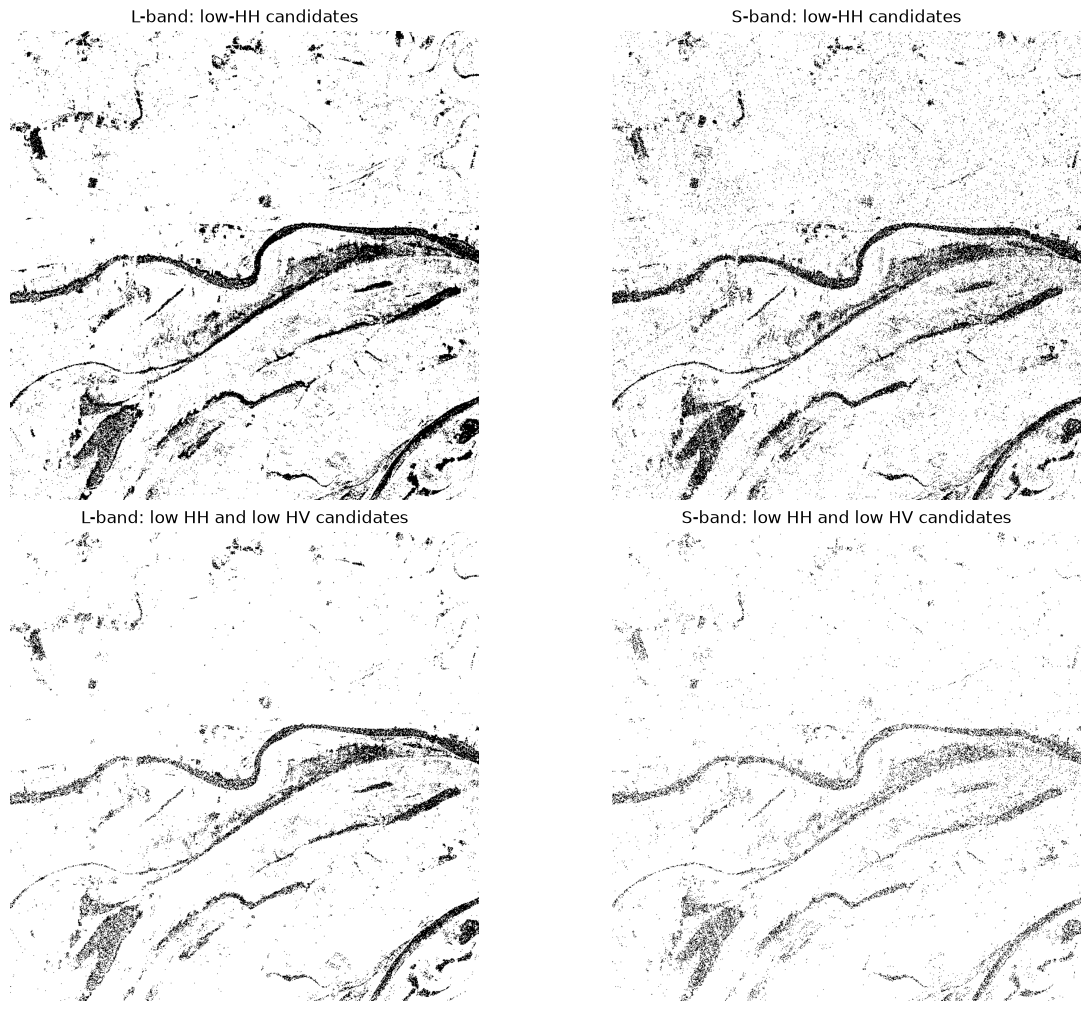

In [23]:
import numpy as np
import matplotlib.pyplot as plt

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for col, band in enumerate(("L-band", "S-band")):
    hh = aligned[band]["hh"]
    hv = arrays[band]["hv"]

    # Match HV to the same coordinate indices used in the aligned HH grid.
    if band == "L-band":
        hv_aligned = hv
    else:
        hv_aligned = hv[
            np.ix_(
                np.abs(arrays["S-band"]["y"][None, :] - y_ref[:, None]).argmin(axis=1),
                np.abs(arrays["S-band"]["x"][None, :] - x_ref[:, None]).argmin(axis=1),
            )
        ]

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hv_db = np.full(hh.shape, np.nan, dtype=np.float32)

    ok_hh = joint_valid & np.isfinite(hh) & (hh > 0)
    ok_hv = joint_valid & np.isfinite(hv_aligned) & (hv_aligned > 0)

    hh_db[ok_hh] = 10 * np.log10(hh[ok_hh])
    hv_db[ok_hv] = 10 * np.log10(hv_aligned[ok_hv])

    # Separate exploratory 10th-percentile cutoffs, reported for transparency.
    hh_cut = np.nanpercentile(hh_db, 10)
    hv_cut = np.nanpercentile(hv_db, 10)

    low_hh = ok_hh & (hh_db <= hh_cut)
    low_hh_hv = low_hh & ok_hv & (hv_db <= hv_cut)

    axes[0, col].imshow(low_hh, cmap="gray_r", vmin=0, vmax=1, origin="upper")
    axes[0, col].set_title(f"{band}: low-HH candidates")
    axes[0, col].set_axis_off()

    axes[1, col].imshow(low_hh_hv, cmap="gray_r", vmin=0, vmax=1, origin="upper")
    axes[1, col].set_title(f"{band}: low HH and low HV candidates")
    axes[1, col].set_axis_off()

    print(
        f"{band}: HH cutoff={hh_cut:.2f} dB; HV cutoff={hv_cut:.2f} dB; "
        f"low-HH={int(low_hh.sum())}; low-HH+HV={int(low_hh_hv.sum())}"
    )

plt.show()

Shared grid shape: (800, 800)
Valid shared pixels: 640000
Both bands low-HH: 35651
Both bands low-HH and low-HV: 10916


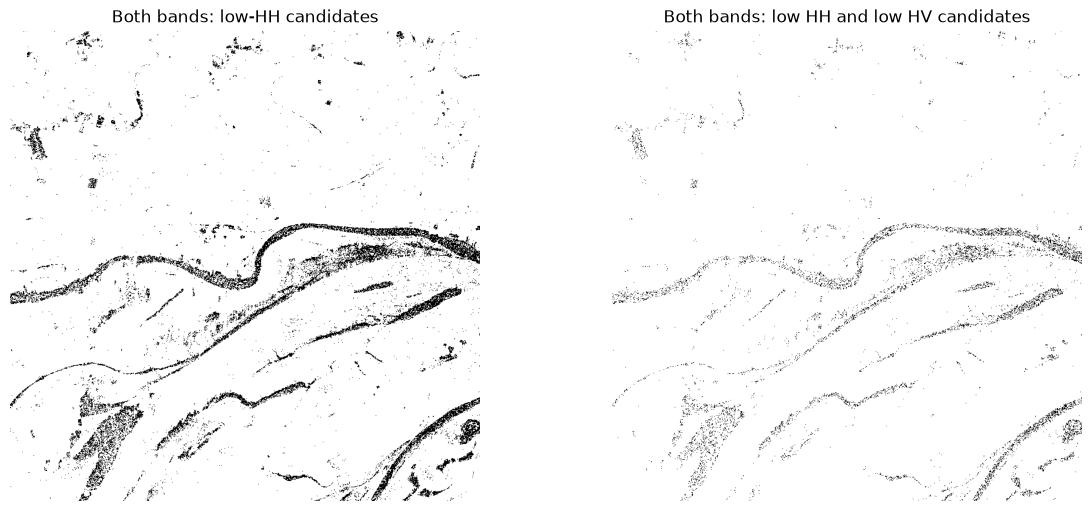

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Map the shared grid coordinates to each band's window indices.
def coordinate_indices(source, target, label):
    indices = np.abs(source[None, :] - target[:, None]).argmin(axis=1)
    matched = np.isclose(source[indices], target, atol=1e-6)
    if not np.all(matched):
        raise ValueError(f"{label}: some coordinates did not match")
    return indices

x_ref = x_ref
y_ref = y_ref

consensus = {}

for band in ("L-band", "S-band"):
    a = arrays[band]

    # Align this band's HH, HV and validity mask to the common grid.
    cols = coordinate_indices(a["x"], x_ref, f"{band} X")
    rows = coordinate_indices(a["y"], y_ref, f"{band} Y")

    hh = a["hh"][np.ix_(rows, cols)]
    hv = a["hv"][np.ix_(rows, cols)]
    valid = a["valid"][np.ix_(rows, cols)] & joint_valid

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hv_db = np.full(hv.shape, np.nan, dtype=np.float32)

    ok_hh = valid & np.isfinite(hh) & (hh > 0)
    ok_hv = valid & np.isfinite(hv) & (hv > 0)

    hh_db[ok_hh] = 10 * np.log10(hh[ok_hh])
    hv_db[ok_hv] = 10 * np.log10(hv[ok_hv])

    hh_cut = np.nanpercentile(hh_db, 10)
    hv_cut = np.nanpercentile(hv_db, 10)

    low_hh = ok_hh & (hh_db <= hh_cut)
    low_hh_hv = low_hh & ok_hv & (hv_db <= hv_cut)

    consensus[band] = {
        "low_hh": low_hh,
        "low_hh_hv": low_hh_hv,
    }

both_bands_low_hh = (
    consensus["L-band"]["low_hh"] & consensus["S-band"]["low_hh"]
)
both_bands_low_hh_hv = (
    consensus["L-band"]["low_hh_hv"] & consensus["S-band"]["low_hh_hv"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].imshow(both_bands_low_hh, cmap="gray_r", vmin=0, vmax=1, origin="upper")
axes[0].set_title("Both bands: low-HH candidates")
axes[0].set_axis_off()

axes[1].imshow(
    both_bands_low_hh_hv,
    cmap="gray_r",
    vmin=0,
    vmax=1,
    origin="upper",
)
axes[1].set_title("Both bands: low HH and low HV candidates")
axes[1].set_axis_off()

print("Shared grid shape:", both_bands_low_hh.shape)
print("Valid shared pixels:", int(joint_valid.sum()))
print("Both bands low-HH:", int(both_bands_low_hh.sum()))
print("Both bands low-HH and low-HV:", int(both_bands_low_hh_hv.sum()))

plt.show()

L-band HH: 2nd–98th percentile = -19.05 to 0.42 dB
L-band HV: 2nd–98th percentile = -25.81 to -7.98 dB
S-band HH: 2nd–98th percentile = -18.49 to -0.91 dB
S-band HV: 2nd–98th percentile = -22.98 to -8.33 dB


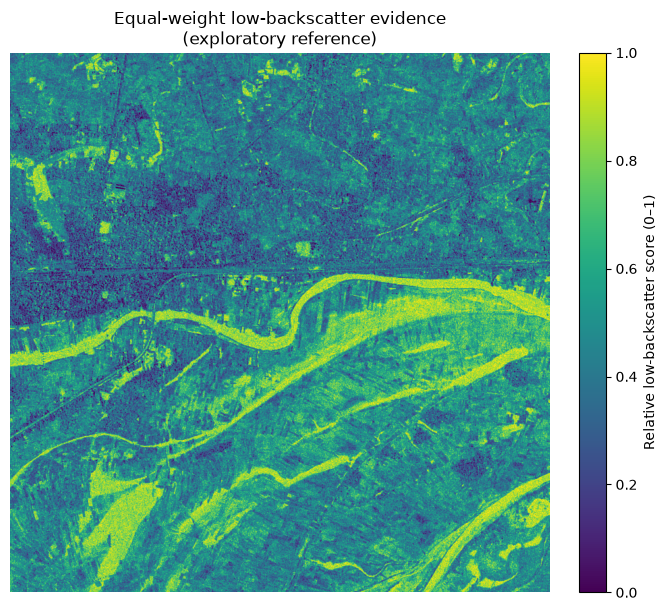

Shared valid pixels: 640000 of 640000
Equal-weight score percentiles (10, 50, 90): [0.263 0.465 0.761]


In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Build HH and HV dB arrays for each band on the shared 800 × 800 grid.
joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]
db = {}

for band in ("L-band", "S-band"):
    hh = aligned[band]["hh"]

    # Align HV to the shared coordinate grid.
    a = arrays[band]
    cols = np.abs(a["x"][None, :] - x_ref[:, None]).argmin(axis=1)
    rows = np.abs(a["y"][None, :] - y_ref[:, None]).argmin(axis=1)
    hv = a["hv"][np.ix_(rows, cols)]

    for pol, power in (("HH", hh), ("HV", hv)):
        usable = joint_valid & np.isfinite(power) & (power > 0)
        layer_db = np.full(power.shape, np.nan, dtype=np.float32)
        layer_db[usable] = 10 * np.log10(power[usable])
        db[(band, pol)] = layer_db

# Use robust percentiles to put each channel on a comparable 0–1 scale.
# This is display/analysis normalization, not yet a learned fusion weight.
normalized = {}
for key, layer_db in db.items():
    vals = layer_db[joint_valid & np.isfinite(layer_db)]
    lo, hi = np.percentile(vals, [2, 98])
    normalized[key] = np.clip((layer_db - lo) / (hi - lo), 0, 1)
    print(f"{key[0]} {key[1]}: 2nd–98th percentile = {lo:.2f} to {hi:.2f} dB")

# Low normalized backscatter is the exploratory water-like evidence.
# Keep each band/polarization visible so the combined score is interpretable.
evidence_stack = np.stack([
    1 - normalized[("L-band", "HH")],
    1 - normalized[("L-band", "HV")],
    1 - normalized[("S-band", "HH")],
    1 - normalized[("S-band", "HV")],
])

# Equal-weight reference score for now. Adaptive weights come only after
# we estimate channel quality and validate the resulting classifications.
equal_score = np.nanmean(evidence_stack, axis=0)
equal_score[~joint_valid] = np.nan

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(equal_score, cmap="viridis", vmin=0, vmax=1, origin="upper")
ax.set_title("Equal-weight low-backscatter evidence\n(exploratory reference)")
ax.set_axis_off()
fig.colorbar(im, ax=ax, label="Relative low-backscatter score (0–1)")
plt.show()

print("Shared valid pixels:", int(joint_valid.sum()), "of", joint_valid.size)
print(
    "Equal-weight score percentiles (10, 50, 90):",
    np.nanpercentile(equal_score, [10, 50, 90]).round(3)
)

L-band HH: local std p50/p90 = [3.299 4.714]
L-band HV: local std p50/p90 = [3.337 4.242]
S-band HH: local std p50/p90 = [3.39 4.56]
S-band HV: local std p50/p90 = [3.144 3.662]


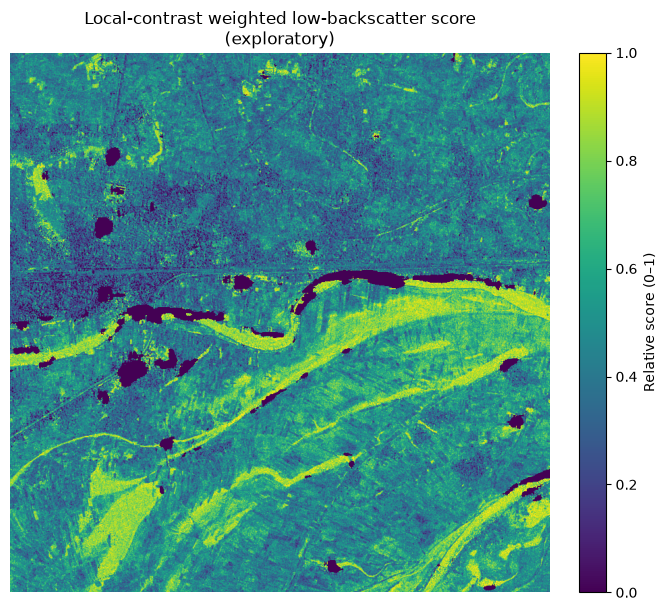

Adaptive score percentiles (10, 50, 90): [0.243 0.463 0.754]


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter

# joint_valid, db, and normalized were created in the previous cell.
# Estimate reliability from local texture: lower local variability gets
# higher reliability. Use 21 × 21 pixel neighborhoods.
window = 21
reliability = {}

for key, layer_db in db.items():
    valid = joint_valid & np.isfinite(layer_db)

    # Replace invalid values before local filtering, then normalize by
    # the local valid count so masked pixels do not bias neighborhood means.
    values = np.where(valid, layer_db, 0).astype(np.float32)
    weights = valid.astype(np.float32)

    local_count = uniform_filter(weights, size=window, mode="nearest")
    local_mean = uniform_filter(values, size=window, mode="nearest") / np.maximum(local_count, 1e-6)
    local_sq_mean = uniform_filter(values**2, size=window, mode="nearest") / np.maximum(local_count, 1e-6)
    local_std = np.sqrt(np.maximum(local_sq_mean - local_mean**2, 0))

    # Convert variability to relative reliability in [0, 1].
    # This is a transparent heuristic, not a validated quality metric.
    scale = np.nanpercentile(local_std[valid], 90)
    rel = 1 - np.clip(local_std / max(scale, 1e-6), 0, 1)
    rel[~valid] = np.nan
    reliability[key] = rel

    print(
        f"{key[0]} {key[1]}: local std p50/p90 = "
        f"{np.nanpercentile(local_std[valid], [50, 90]).round(3)}"
    )

# Normalize the four reliability layers into per-pixel adaptive weights.
rel_stack = np.stack([reliability[k] for k in [
    ("L-band", "HH"), ("L-band", "HV"),
    ("S-band", "HH"), ("S-band", "HV")
]])

weight_sum = np.nansum(rel_stack, axis=0)
adaptive_weights = rel_stack / np.maximum(weight_sum, 1e-8)

# Fuse the already normalized low-backscatter evidence using those weights.
evidence_stack = np.stack([
    1 - normalized[("L-band", "HH")],
    1 - normalized[("L-band", "HV")],
    1 - normalized[("S-band", "HH")],
    1 - normalized[("S-band", "HV")],
])

adaptive_score = np.nansum(adaptive_weights * evidence_stack, axis=0)
adaptive_score[~joint_valid] = np.nan

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(adaptive_score, cmap="viridis", vmin=0, vmax=1, origin="upper")
ax.set_title("Local-contrast weighted low-backscatter score\n(exploratory)")
ax.set_axis_off()
fig.colorbar(im, ax=ax, label="Relative score (0–1)")
plt.show()

print(
    "Adaptive score percentiles (10, 50, 90):",
    np.nanpercentile(adaptive_score, [10, 50, 90]).round(3)
)


Compared pixels: 640000
Absolute difference percentiles (50, 90, 99): [0.0209 0.0824 0.691 ]
Mean absolute difference: 0.0459


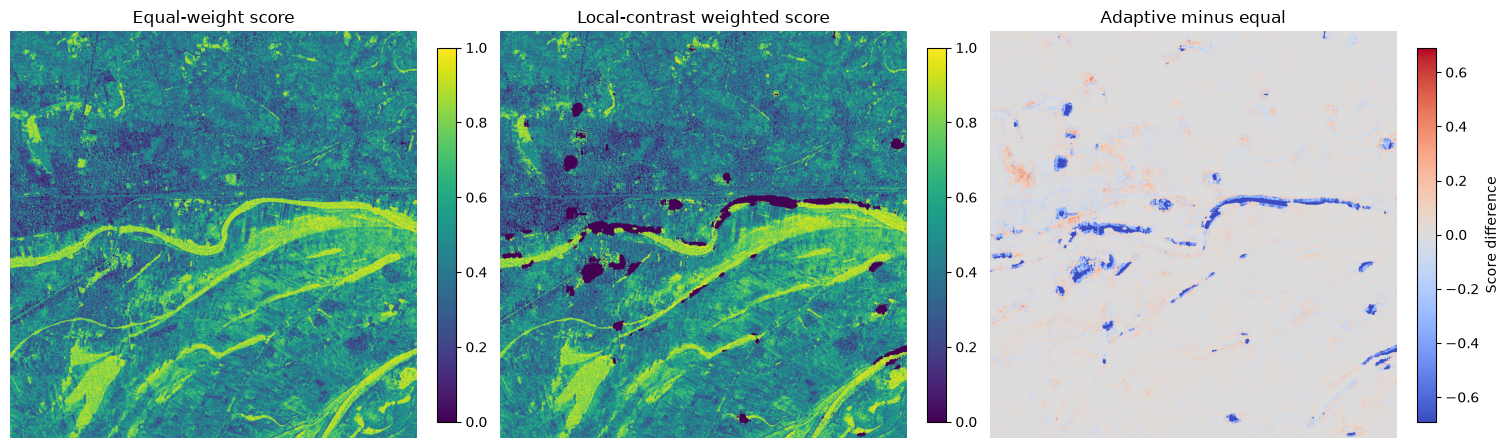

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Compare equal-weight and local-contrast weighted scores
valid_compare = (
    joint_valid
    & np.isfinite(equal_score)
    & np.isfinite(adaptive_score)
)

difference = np.full(equal_score.shape, np.nan, dtype=np.float32)
difference[valid_compare] = adaptive_score[valid_compare] - equal_score[valid_compare]

print("Compared pixels:", int(valid_compare.sum()))
print(
    "Absolute difference percentiles (50, 90, 99):",
    np.percentile(np.abs(difference[valid_compare]), [50, 90, 99]).round(4)
)
print(
    "Mean absolute difference:",
    round(float(np.mean(np.abs(difference[valid_compare]))), 4)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

im0 = axes[0].imshow(equal_score, cmap="viridis", vmin=0, vmax=1, origin="upper")
axes[0].set_title("Equal-weight score")
axes[0].set_axis_off()
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(adaptive_score, cmap="viridis", vmin=0, vmax=1, origin="upper")
axes[1].set_title("Local-contrast weighted score")
axes[1].set_axis_off()
fig.colorbar(im1, ax=axes[1], fraction=0.046)

lim = np.nanpercentile(np.abs(difference[valid_compare]), 99)
im2 = axes[2].imshow(difference, cmap="coolwarm", vmin=-lim, vmax=lim, origin="upper")
axes[2].set_title("Adaptive minus equal")
axes[2].set_axis_off()
fig.colorbar(im2, ax=axes[2], fraction=0.046, label="Score difference")

plt.show()

L-band, 5th percentile: cutoff=-17.08 dB; candidates=32002 / 640000
L-band, 10th percentile: cutoff=-15.02 dB; candidates=64000 / 640000
L-band, 15th percentile: cutoff=-13.60 dB; candidates=96000 / 640000
S-band, 5th percentile: cutoff=-16.45 dB; candidates=32000 / 640000
S-band, 10th percentile: cutoff=-14.51 dB; candidates=64000 / 640000
S-band, 15th percentile: cutoff=-13.22 dB; candidates=96000 / 640000


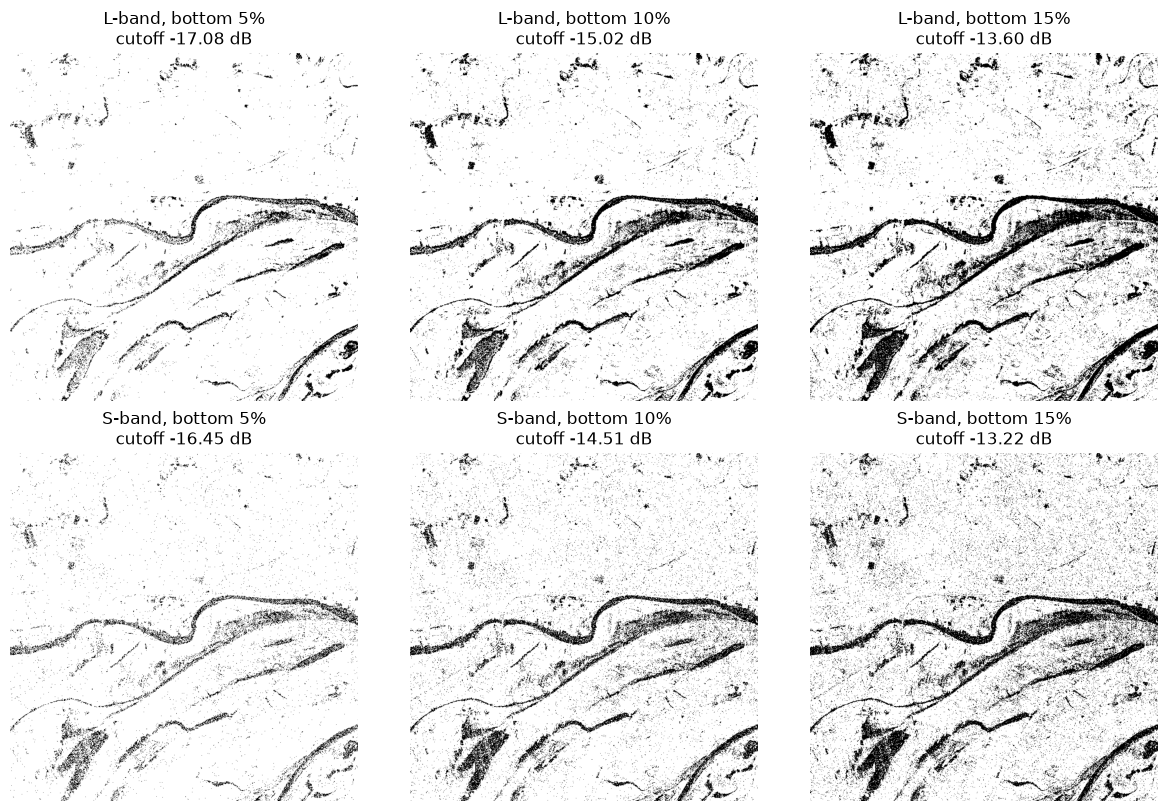

In [29]:
import numpy as np
import matplotlib.pyplot as plt

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]
percentiles = (5, 10, 15)

fig, axes = plt.subplots(
    2, 3, figsize=(12, 8), constrained_layout=True
)

for row, band in enumerate(("L-band", "S-band")):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    for col, percentile in enumerate(percentiles):
        cutoff = np.percentile(hh_db[usable], percentile)
        candidate = usable & (hh_db <= cutoff)

        axes[row, col].imshow(
            candidate,
            cmap="gray_r",
            vmin=0,
            vmax=1,
            origin="upper",
        )
        axes[row, col].set_title(
            f"{band}, bottom {percentile}%\ncutoff {cutoff:.2f} dB"
        )
        axes[row, col].set_axis_off()

        print(
            f"{band}, {percentile}th percentile: "
            f"cutoff={cutoff:.2f} dB; "
            f"candidates={int(candidate.sum())} / {int(joint_valid.sum())}"
        )

plt.show()

In [30]:
import numpy as np

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]

for percentile in (5, 10, 15):
    candidates = {}

    for band in ("L-band", "S-band"):
        hh = aligned[band]["hh"]
        usable = joint_valid & np.isfinite(hh) & (hh > 0)

        hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
        hh_db[usable] = 10 * np.log10(hh[usable])

        cutoff = np.percentile(hh_db[usable], percentile)
        candidates[band] = usable & (hh_db <= cutoff)

    both = candidates["L-band"] & candidates["S-band"]
    either = candidates["L-band"] | candidates["S-band"]
    union_count = int(either.sum())

    # Jaccard overlap: shared candidates / all candidates from either band.
    jaccard = int(both.sum()) / union_count if union_count else np.nan

    print(
        f"{percentile}% threshold | "
        f"L={int(candidates['L-band'].sum())}, "
        f"S={int(candidates['S-band'].sum())}, "
        f"shared={int(both.sum())}, "
        f"union={union_count}, "
        f"Jaccard={jaccard:.3f}"
    )

5% threshold | L=32002, S=32000, shared=13783, union=50219, Jaccard=0.274
10% threshold | L=64000, S=64000, shared=35651, union=92349, Jaccard=0.386
15% threshold | L=96000, S=96000, shared=55475, union=136525, Jaccard=0.406


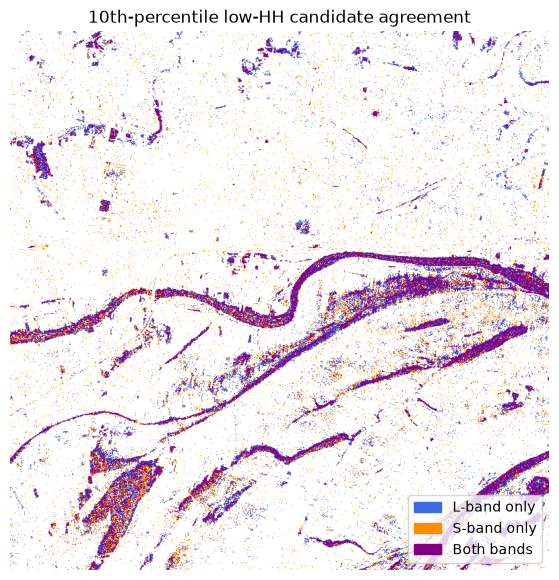

L-band only: 28349
S-band only: 28349
Both bands: 35651
Neither: 547651


In [31]:
import numpy as np
import matplotlib.pyplot as plt

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]
threshold_percentile = 10
candidates = {}

for band in ("L-band", "S-band"):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    cutoff = np.percentile(hh_db[usable], threshold_percentile)
    candidates[band] = usable & (hh_db <= cutoff)

l = candidates["L-band"]
s = candidates["S-band"]

# 0 = neither band, 1 = L-band only, 2 = S-band only, 3 = both.
agreement = np.zeros(l.shape, dtype=np.uint8)
agreement[l] += 1
agreement[s] += 2

agreement = np.ma.masked_where(~joint_valid, agreement)

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["white", "royalblue", "darkorange", "purple"])

plt.figure(figsize=(8, 7))
plt.imshow(agreement, cmap=cmap, vmin=0, vmax=3, origin="upper")
plt.title("10th-percentile low-HH candidate agreement")
plt.axis("off")

# Legend keys
import matplotlib.patches as mpatches
legend = [
    mpatches.Patch(color="royalblue", label="L-band only"),
    mpatches.Patch(color="darkorange", label="S-band only"),
    mpatches.Patch(color="purple", label="Both bands"),
]
plt.legend(handles=legend, loc="lower right")
plt.show()

print("L-band only:", int(np.sum(l & ~s)))
print("S-band only:", int(np.sum(s & ~l)))
print("Both bands:", int(np.sum(l & s)))
print("Neither:", int(np.sum(joint_valid & ~l & ~s)))

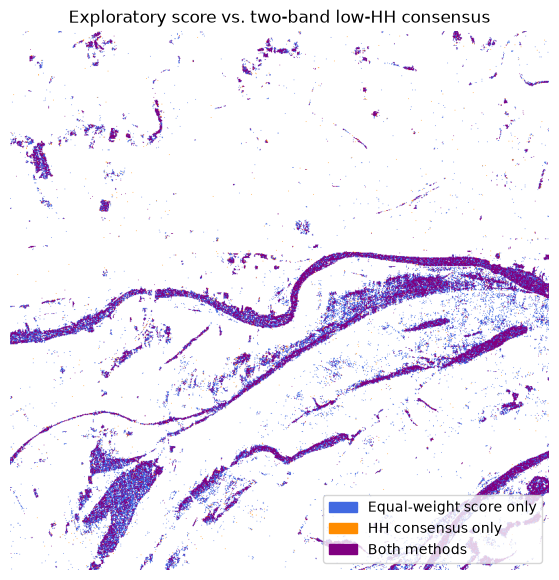

Equal-weight score cutoff (90th percentile): 0.761
Score candidates: 64000
HH consensus candidates: 35651
Overlap: 34033
Jaccard overlap: 0.519


In [32]:
import numpy as np
import matplotlib.pyplot as plt

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]

# Equal-weight score was built from normalized low-backscatter evidence.
# Define the top 10% of scores as exploratory candidates.
score_values = equal_score[joint_valid & np.isfinite(equal_score)]
score_cutoff = np.percentile(score_values, 90)
score_candidate = joint_valid & (equal_score >= score_cutoff)

# Rebuild the 10th-percentile low-HH agreement mask.
low_hh = {}

for band in ("L-band", "S-band"):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    cutoff = np.percentile(hh_db[usable], 10)
    low_hh[band] = usable & (hh_db <= cutoff)

consensus_candidate = low_hh["L-band"] & low_hh["S-band"]

# 0 = neither, 1 = score only, 2 = HH consensus only, 3 = both.
comparison = np.zeros(equal_score.shape, dtype=np.uint8)
comparison[score_candidate] += 1
comparison[consensus_candidate] += 2
comparison = np.ma.masked_where(~joint_valid, comparison)

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

plt.figure(figsize=(8, 7))
plt.imshow(
    comparison,
    cmap=ListedColormap(["white", "royalblue", "darkorange", "purple"]),
    vmin=0,
    vmax=3,
    origin="upper",
)
plt.title("Exploratory score vs. two-band low-HH consensus")
plt.axis("off")
plt.legend(
    handles=[
        Patch(color="royalblue", label="Equal-weight score only"),
        Patch(color="darkorange", label="HH consensus only"),
        Patch(color="purple", label="Both methods"),
    ],
    loc="lower right",
)
plt.show()

print("Equal-weight score cutoff (90th percentile):", round(float(score_cutoff), 3))
print("Score candidates:", int(score_candidate.sum()))
print("HH consensus candidates:", int(consensus_candidate.sum()))
print("Overlap:", int((score_candidate & consensus_candidate).sum()))
print("Jaccard overlap:",
      round(float((score_candidate & consensus_candidate).sum()
                  / (score_candidate | consensus_candidate).sum()), 3))

In [33]:
pixel_area_m2 = 10 * 10

masks = {
    "Equal-weight score (top 10%)": score_candidate,
    "Two-band low-HH consensus": consensus_candidate,
    "Overlap": score_candidate & consensus_candidate,
}

for label, mask in masks.items():
    count = int(np.count_nonzero(mask & joint_valid))
    area_m2 = count * pixel_area_m2
    area_ha = area_m2 / 10_000
    area_km2 = area_m2 / 1_000_000

    print(
        f"{label}: {count:,} pixels | "
        f"{area_ha:.2f} ha | {area_km2:.4f} km²"
    )

Equal-weight score (top 10%): 64,000 pixels | 640.00 ha | 6.4000 km²
Two-band low-HH consensus: 35,651 pixels | 356.51 ha | 3.5651 km²
Overlap: 34,033 pixels | 340.33 ha | 3.4033 km²


Connected candidate patches: 3300
Largest patch sizes (pixels): [5524, 2095, 1614, 1454, 1099, 932, 896, 751, 634, 571]
Largest patch areas (ha): [55.24, 20.95, 16.14, 14.54, 10.99, 9.32, 8.96, 7.51, 6.34, 5.71]
Pixels in largest patch: 5524
Share of candidate pixels in largest patch: 0.155


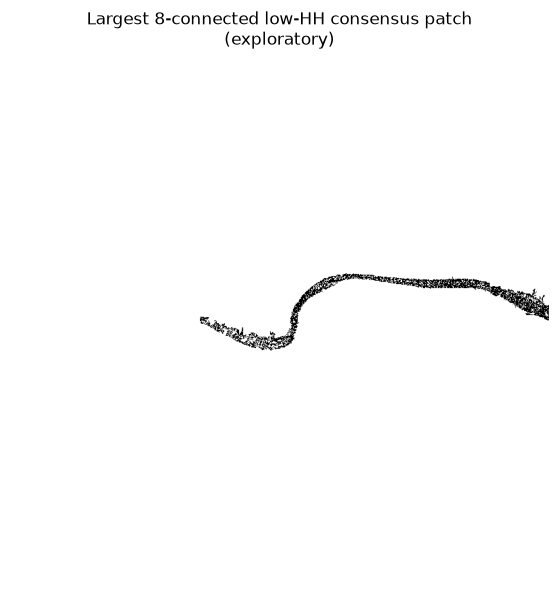

In [34]:
import numpy as np
from scipy import ndimage

# 8-connected components among two-band low-HH candidates.
mask = consensus_candidate & joint_valid
structure = np.ones((3, 3), dtype=np.uint8)

labels, n_components = ndimage.label(mask, structure=structure)
sizes = np.bincount(labels.ravel())[1:]  # omit background label 0

if sizes.size:
    order = np.argsort(sizes)[::-1]
    top_sizes = sizes[order[:10]]
    print("Connected candidate patches:", int(n_components))
    print("Largest patch sizes (pixels):", top_sizes.tolist())
    print("Largest patch areas (ha):", (top_sizes * 0.01).round(2).tolist())
    print("Pixels in largest patch:", int(top_sizes[0]))
    print("Share of candidate pixels in largest patch:",
          round(float(top_sizes[0] / mask.sum()), 3))
else:
    print("No candidate patches found.")

# Visualize the largest component only.
if sizes.size:
    largest_id = int(order[0] + 1)
    largest_patch = labels == largest_id

    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 7))
    plt.imshow(largest_patch, cmap="gray_r", origin="upper")
    plt.title("Largest 8-connected low-HH consensus patch\n(exploratory)")
    plt.axis("off")
    plt.show()

In [35]:
import numpy as np
from scipy import ndimage

joint_valid = aligned["L-band"]["valid"] & aligned["S-band"]["valid"]
structure = np.ones((3, 3), dtype=np.uint8)

def low_hh_mask(band, percentile):
    hh = aligned[band]["hh"]
    usable = joint_valid & np.isfinite(hh) & (hh > 0)

    hh_db = np.full(hh.shape, np.nan, dtype=np.float32)
    hh_db[usable] = 10 * np.log10(hh[usable])

    cutoff = np.percentile(hh_db[usable], percentile)
    return usable & (hh_db <= cutoff)

for percentile in (5, 10, 15):
    consensus = (
        low_hh_mask("L-band", percentile)
        & low_hh_mask("S-band", percentile)
    )

    labels, n = ndimage.label(consensus, structure=structure)
    sizes = np.bincount(labels.ravel())[1:]
    sizes = np.sort(sizes)[::-1]

    print(f"\nBottom {percentile}% HH consensus")
    print("Candidate pixels:", int(consensus.sum()))
    print("Connected patches:", int(n))
    print("Largest 5 patch sizes (pixels):", sizes[:5].tolist())
    print("Largest patch area (ha):", round(float(sizes[0] * 0.01), 2) if sizes.size else 0)


Bottom 5% HH consensus
Candidate pixels: 13783
Connected patches: 3149
Largest 5 patch sizes (pixels): [250, 247, 244, 229, 227]
Largest patch area (ha): 2.5

Bottom 10% HH consensus
Candidate pixels: 35651
Connected patches: 3300
Largest 5 patch sizes (pixels): [5524, 2095, 1614, 1454, 1099]
Largest patch area (ha): 55.24

Bottom 15% HH consensus
Candidate pixels: 55475
Connected patches: 4745
Largest 5 patch sizes (pixels): [15401, 5748, 3002, 2363, 1931]
Largest patch area (ha): 154.01
